In [ ]:
!pip install -q shap xgboost scikit-learn

In [ ]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded))

Saving pzt_dataset_extracted.csv to pzt_dataset_extracted.csv
['pzt_dataset_extracted.csv']


In [ ]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import (train_test_split, GridSearchCV, RepeatedKFold,
                                     cross_validate, learning_curve)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

CSV = "pzt_dataset_extracted.csv"   # file uploaded in the previous cell
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

SEED = 42          # not stated in the paper
CV_FOLDS = 5       # not stated in the paper for GridSearchCV
FEATURES = ["a/b", "Piezo_Area(%)"]
FEAT_LABELS = ["Apex-to-base ratio (a/b)", "Piezoelectric material coverage (%)"]
TARGETS = ["Voltage(V)", "Power(mW)", "PowerDensity(uW/mm3)", "EigenFrequency(Hz)"]

# Grids contain the best values reported in the paper's Table 6
GRIDS = {
    "RF": (RandomForestRegressor(random_state=SEED), {
        "n_estimators": [100, 300], "max_depth": [10, 20, 30],
        "min_samples_split": [2, 5], "min_samples_leaf": [1, 2], "bootstrap": [True]}),
    "XGBoost": (XGBRegressor(random_state=SEED, verbosity=0), {
        "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 6, 9],
        "n_estimators": [200, 300], "subsample": [0.8, 1.0],
        "colsample_bytree": [1.0], "gamma": [0, 0.1]}),
    "SVR": (SVR(), {
        "C": [1, 10, 100], "epsilon": [0.01, 0.1],
        "gamma": ["scale", "auto", 1], "kernel": ["rbf"]}),
    "GBR": (GradientBoostingRegressor(random_state=SEED), {
        "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5],
        "n_estimators": [100, 300], "subsample": [0.8, 1.0],
        "max_features": ["sqrt"], "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 4]}),
}

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

In [ ]:
df = pd.read_csv(CSV)
X, Y = df[FEATURES], df[TARGETS]
X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.20, random_state=SEED)
print(f"rows={len(df)}  train={len(X_tr)}  test={len(X_te)}")

# scaler fitted on training data only (used by SVR; trees are scale-invariant)
scaler = StandardScaler().fit(X_tr)

def make_estimator(name, params=None):
    base, _ = GRIDS[name]
    est = base.__class__(**{**base.get_params(), **(params or {})})
    return make_pipeline(StandardScaler(), est) if name == "SVR" else est

rows=70  train=56  test=14


Voltage(V)             RF       R2_test=0.9772
Voltage(V)             XGBoost  R2_test=0.9854
Voltage(V)             SVR      R2_test=0.9944
Voltage(V)             GBR      R2_test=0.9772


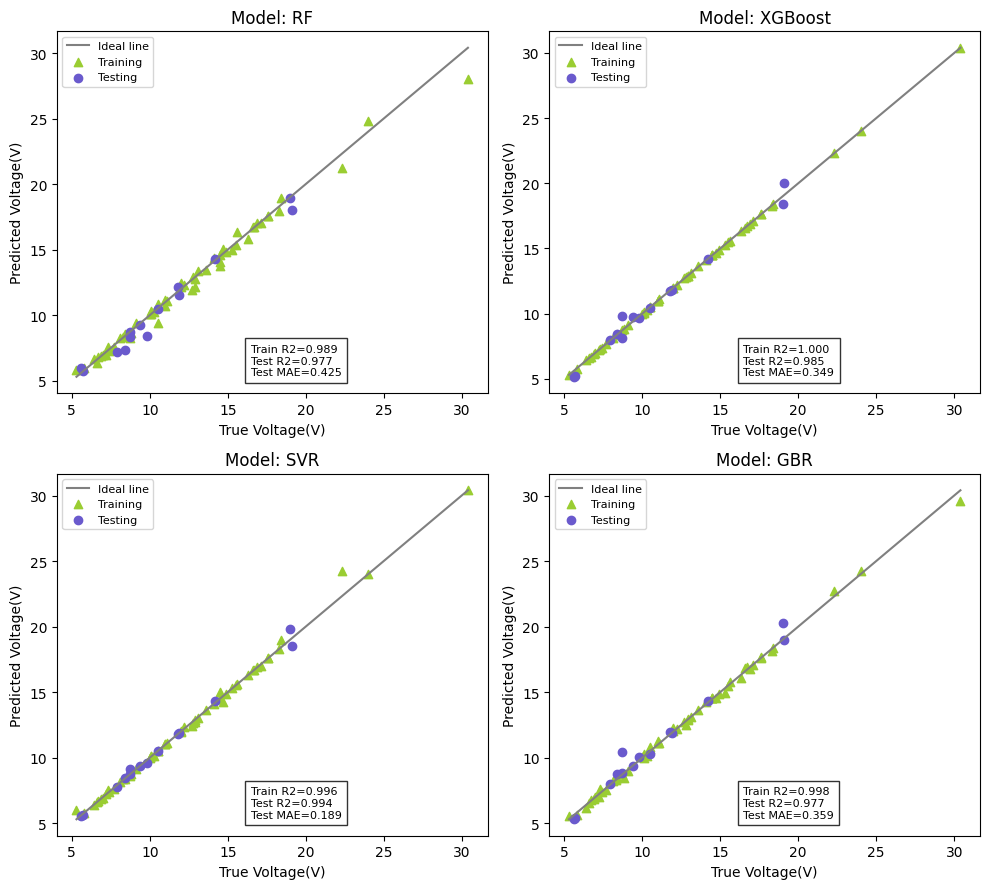

Power(mW)              RF       R2_test=0.9483
Power(mW)              XGBoost  R2_test=0.9918
Power(mW)              SVR      R2_test=0.9995
Power(mW)              GBR      R2_test=0.9954


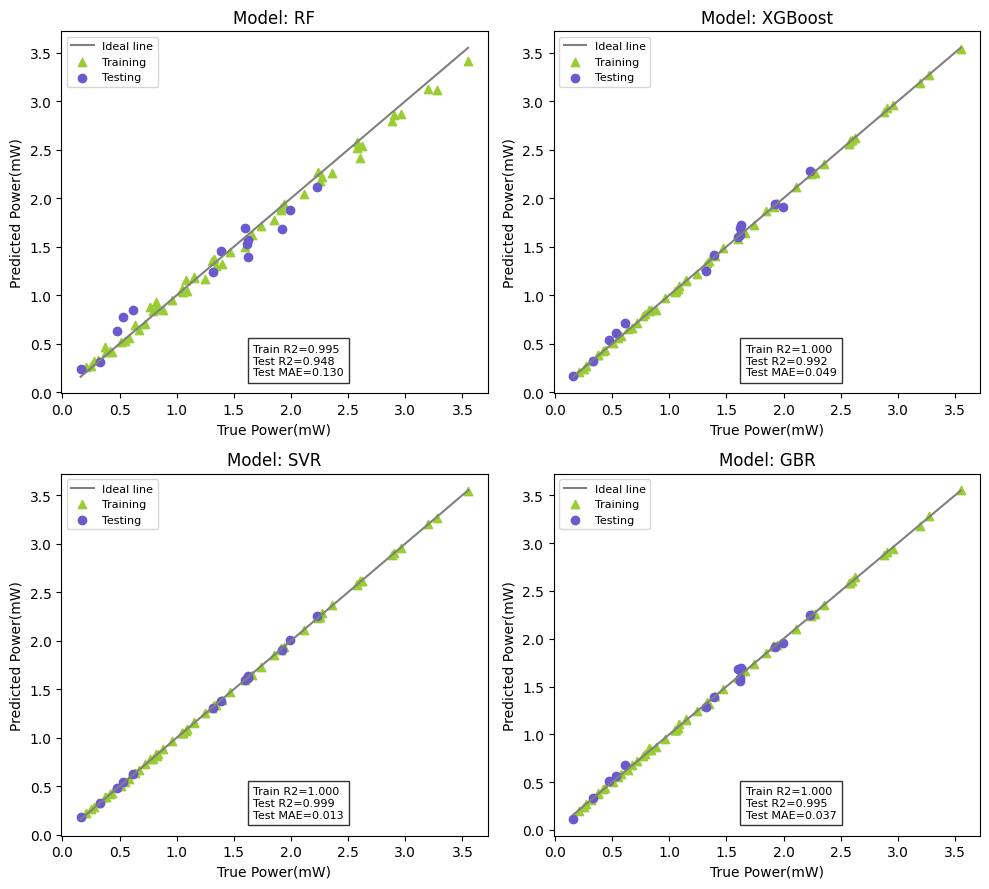

PowerDensity(uW/mm3)   RF       R2_test=0.9641
PowerDensity(uW/mm3)   XGBoost  R2_test=0.9739
PowerDensity(uW/mm3)   SVR      R2_test=0.9917
PowerDensity(uW/mm3)   GBR      R2_test=0.9427


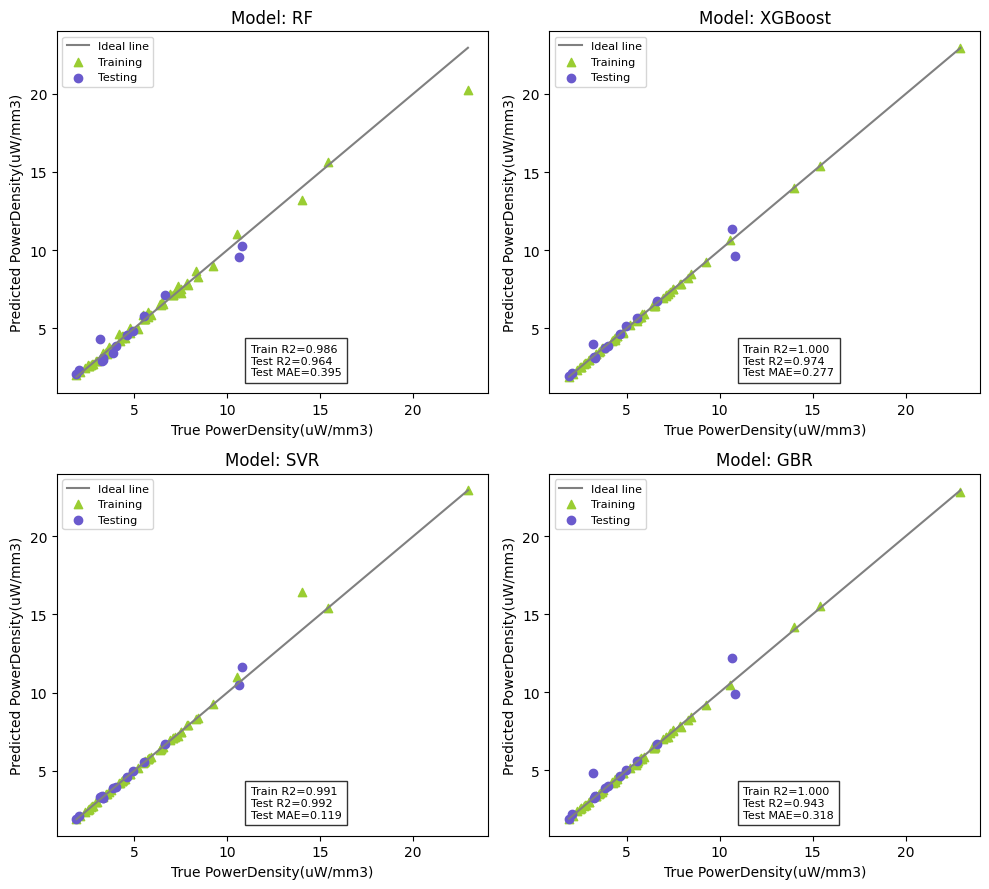

EigenFrequency(Hz)     RF       R2_test=0.8629
EigenFrequency(Hz)     XGBoost  R2_test=0.9724
EigenFrequency(Hz)     SVR      R2_test=0.9726
EigenFrequency(Hz)     GBR      R2_test=0.9834


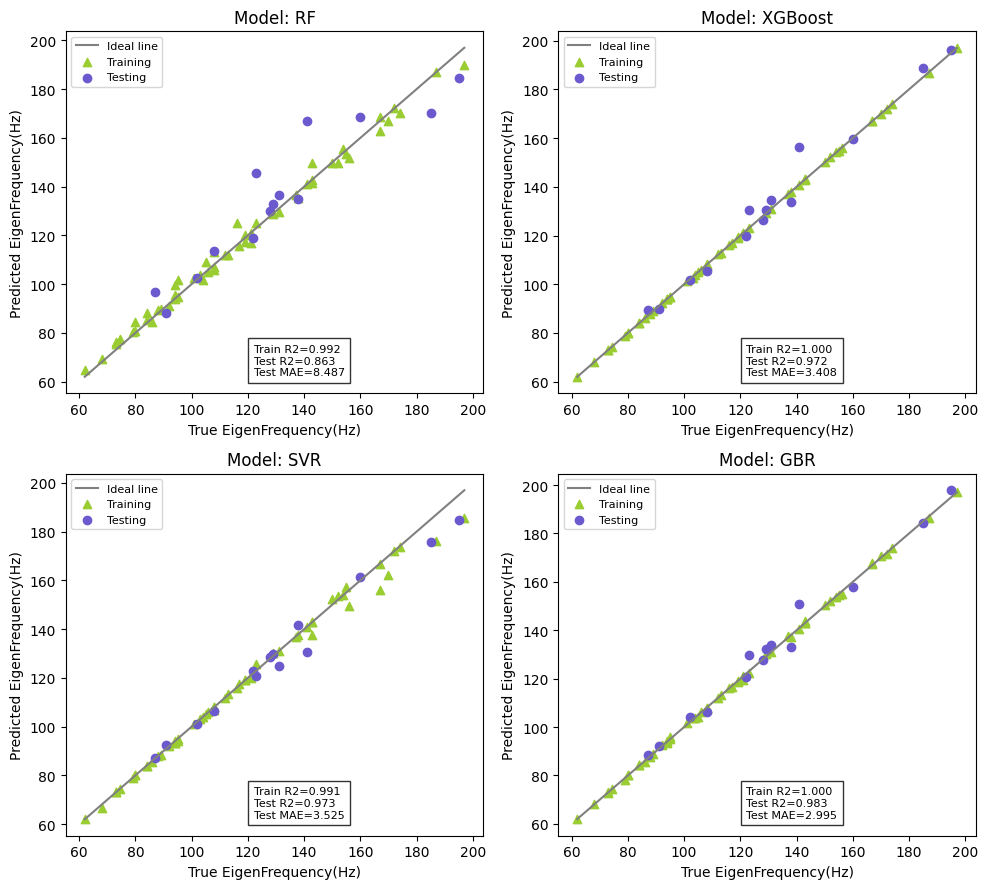

In [ ]:
rows, fitted = [], {}
for tgt in TARGETS:
    y_tr, y_te = Y_tr[tgt].values, Y_te[tgt].values
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))
    for ax, name in zip(axes.ravel(), GRIDS):
        base, grid = GRIDS[name]
        if name == "SVR":
            pipe = make_pipeline(StandardScaler(), base)
            grid = {f"svr__{k}": v for k, v in grid.items()}
        else:
            pipe = base
        gs = GridSearchCV(pipe, grid, cv=CV_FOLDS, scoring="r2", n_jobs=-1).fit(X_tr, y_tr)
        best = gs.best_estimator_
        fitted[(tgt, name)] = (best, gs.best_params_)
        p_tr, p_te = best.predict(X_tr), best.predict(X_te)
        rows.append(dict(Target=tgt, Model=name,
                         R2_train=r2_score(y_tr, p_tr), R2_test=r2_score(y_te, p_te),
                         RMSE_train=rmse(y_tr, p_tr), RMSE_test=rmse(y_te, p_te),
                         MAE_train=mean_absolute_error(y_tr, p_tr), MAE_test=mean_absolute_error(y_te, p_te),
                         best_params=str(gs.best_params_)))
        lo, hi = min(y_tr.min(), y_te.min()), max(y_tr.max(), y_te.max())
        ax.plot([lo, hi], [lo, hi], color="grey", label="Ideal line")
        ax.scatter(y_tr, p_tr, marker="^", c="yellowgreen", label="Training")
        ax.scatter(y_te, p_te, c="slateblue", label="Testing")
        ax.set_title(f"Model: {name}"); ax.set_xlabel(f"True {tgt}"); ax.set_ylabel(f"Predicted {tgt}")
        ax.text(0.45, 0.05, f"Train R2={rows[-1]['R2_train']:.3f}\nTest R2={rows[-1]['R2_test']:.3f}\n"
                            f"Test MAE={rows[-1]['MAE_test']:.3f}", transform=ax.transAxes, fontsize=8,
                bbox=dict(fc="white", alpha=.8))
        ax.legend(loc="upper left", fontsize=8)
        print(f"{tgt:22s} {name:8s} R2_test={rows[-1]['R2_test']:.4f}")
    fig.tight_layout(); fig.savefig(f"{OUT}/parity_{tgt.split('(')[0]}.png", dpi=150); plt.show(); plt.close(fig)

res = pd.DataFrame(rows)
res.to_csv(f"{OUT}/table6_model_performance.csv", index=False)

In [ ]:
shap_summary = []
for tgt in TARGETS:
    for name in GRIDS:
        model, _ = fitted[(tgt, name)]
        if name == "SVR":
            expl = shap.Explainer(model.predict, X_tr)
            sv = expl(X_te).values
        else:
            expl = shap.TreeExplainer(model)
            sv = expl.shap_values(X_te)
        mean_abs = np.abs(sv).mean(axis=0)
        shap_summary.append(dict(Target=tgt, Model=name, **{f"meanAbsSHAP_{f}": m for f, m in zip(FEATURES, mean_abs)}))
        short = tgt.split("(")[0]
        plt.figure(figsize=(6, 3)); plt.barh(FEAT_LABELS[::-1], mean_abs[::-1], color="#0057a8")
        plt.xlabel("Mean Absolute SHAP Value"); plt.title(f"Model: {name} ({short})")
        plt.tight_layout(); plt.savefig(f"{OUT}/shap_bar_{short}_{name}.png", dpi=150); plt.close()
        shap.summary_plot(sv, X_te.rename(columns=dict(zip(FEATURES, FEAT_LABELS))), show=False, cmap=plt.get_cmap("coolwarm"))
        plt.title(f"Model: {name} ({short})"); plt.tight_layout()
        plt.savefig(f"{OUT}/shap_beeswarm_{short}_{name}.png", dpi=150); plt.close()
pd.DataFrame(shap_summary).to_csv(f"{OUT}/shap_importance.csv", index=False)

In [ ]:
rob = []
rkf = RepeatedKFold(n_splits=5, n_repeats=30, random_state=SEED)
for tgt in TARGETS:
    y = Y[tgt].values
    xgb_best, xgb_params = fitted[(tgt, "XGBoost")]
    # repeated CV on the whole dataset
    cv = cross_validate(make_estimator("XGBoost", xgb_params), X, y, cv=rkf, n_jobs=-1,
                        scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
    # learning curve (paper: 24 -> 120 samples = 20%..100% of the 120-sample training set)
    ts, _, val = learning_curve(make_estimator("XGBoost", xgb_params), X_tr, Y_tr[tgt].values,
                                train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], cv=CV_FOLDS,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    # bootstrap prediction intervals (500 models)
    rng = np.random.default_rng(SEED)
    preds = np.empty((500, len(X_te)))
    for b in range(500):
        idx = rng.integers(0, len(X_tr), len(X_tr))
        m = make_estimator("XGBoost", xgb_params).fit(X_tr.iloc[idx], Y_tr[tgt].values[idx])
        preds[b] = m.predict(X_te)
    lo, hi = np.percentile(preds, [2.5, 97.5], axis=0)
    y_te = Y_te[tgt].values
    rob.append(dict(Target=tgt,
        CV_R2=f"{cv['test_r2'].mean():.5f} +/- {cv['test_r2'].std():.5f}",
        CV_RMSE=f"{-cv['test_neg_root_mean_squared_error'].mean():.5f} +/- {cv['test_neg_root_mean_squared_error'].std():.5f}",
        CV_MAE=f"{-cv['test_neg_mean_absolute_error'].mean():.5f}",
        learning_curve_sizes=list(ts), learning_curve_val_RMSE=[round(-v.mean(), 4) for v in val],
        bootstrap_mean_R2=r2_score(y_te, preds.mean(axis=0)),
        PI95_coverage_pct=100 * np.mean((y_te >= lo) & (y_te <= hi)),
        mean_PI_width=float(np.mean(hi - lo))))
pd.DataFrame(rob).to_csv(f"{OUT}/table8_xgboost_robustness.csv", index=False)

In [ ]:
rsm = []
for tgt in TARGETS:
    y_tr, y_te, y = Y_tr[tgt].values, Y_te[tgt].values, Y[tgt].values
    models = {"Quadratic RSM": make_pipeline(PolynomialFeatures(2), LinearRegression()),
              "Cubic RSM": make_pipeline(PolynomialFeatures(3), LinearRegression()),
              "XGBoost": make_estimator("XGBoost", fitted[(tgt, "XGBoost")][1])}
    for mname, m in models.items():
        m.fit(X_tr, y_tr); p = m.predict(X_te)
        cv = cross_validate(m, X, y, cv=rkf, n_jobs=-1, scoring=("r2", "neg_root_mean_squared_error"))
        rsm.append(dict(Target=tgt, Model=mname, Test_R2=r2_score(y_te, p), Test_RMSE=rmse(y_te, p),
                        Test_MAE=mean_absolute_error(y_te, p),
                        CV_R2=cv["test_r2"].mean(), CV_RMSE=-cv["test_neg_root_mean_squared_error"].mean()))
pd.DataFrame(rsm).to_csv(f"{OUT}/table7_rsm_vs_xgboost.csv", index=False)

print("\nDone. Outputs in", OUT)
print(res[["Target", "Model", "R2_test", "RMSE_test", "MAE_test"]].round(4).to_string(index=False))


Done. Outputs in outputs
              Target   Model  R2_test  RMSE_test  MAE_test
          Voltage(V)      RF   0.9772     0.6112    0.4246
          Voltage(V) XGBoost   0.9854     0.4883    0.3488
          Voltage(V)     SVR   0.9944     0.3028    0.1889
          Voltage(V)     GBR   0.9772     0.6106    0.3593
           Power(mW)      RF   0.9483     0.1498    0.1299
           Power(mW) XGBoost   0.9918     0.0596    0.0486
           Power(mW)     SVR   0.9995     0.0154    0.0127
           Power(mW)     GBR   0.9954     0.0449    0.0375
PowerDensity(uW/mm3)      RF   0.9641     0.5094    0.3949
PowerDensity(uW/mm3) XGBoost   0.9739     0.4348    0.2768
PowerDensity(uW/mm3)     SVR   0.9917     0.2446    0.1189
PowerDensity(uW/mm3)     GBR   0.9427     0.6435    0.3185
  EigenFrequency(Hz)      RF   0.8629    11.3114    8.4870
  EigenFrequency(Hz) XGBoost   0.9724     5.0763    3.4077
  EigenFrequency(Hz)     SVR   0.9726     5.0547    3.5251
  EigenFrequency(Hz)     GBR  

In [ ]:
import pandas as pd
for f in ['table6_model_performance','table7_rsm_vs_xgboost','table8_xgboost_robustness','shap_importance']:
    print(f); display(pd.read_csv(f'outputs/{f}.csv'))

table6_model_performance


,Target,Model,R2_train,R2_test,RMSE_train,RMSE_test,MAE_train,MAE_test,best_params
0,Voltage(V),RF,0.989412,0.977163,0.497981,0.611153,0.314619,0.424571,"{'bootstrap': True, 'max_depth': 10, 'min_samp..."
1,Voltage(V),XGBoost,0.999988,0.985422,0.017089,0.488282,0.013860,0.348842,"{'colsample_bytree': 1.0, 'gamma': 0, 'learnin..."
2,Voltage(V),SVR,0.995871,0.994394,0.310975,0.302802,0.116804,0.188928,"{'svr__C': 100, 'svr__epsilon': 0.01, 'svr__ga..."
3,Voltage(V),GBR,0.998336,0.977205,0.197432,0.610590,0.141366,0.359279,"{'learning_rate': 0.05, 'max_depth': 3, 'max_f..."
4,Power(mW),RF,0.994738,0.948302,0.064719,0.149834,0.051275,0.129867,"{'bootstrap': True, 'max_depth': 20, 'min_samp..."
5,Power(mW),XGBoost,0.999835,0.991814,0.011458,0.059621,0.009070,0.048649,"{'colsample_bytree': 1.0, 'gamma': 0, 'learnin..."
6,Power(mW),SVR,0.999920,0.999453,0.008004,0.015412,0.007267,0.012690,"{'svr__C': 100, 'svr__epsilon': 0.01, 'svr__ga..."
7,Power(mW),GBR,0.999865,0.995357,0.010350,0.044901,0.008108,0.037495,"{'learning_rate': 0.2, 'max_depth': 3, 'max_fe..."
8,PowerDensity(uW/mm3),RF,0.986295,0.964121,0.411415,0.509400,0.186034,0.394857,"{'bootstrap': True, 'max_depth': 10, 'min_samp..."
9,PowerDensity(uW/mm3),XGBoost,0.999887,0.973863,0.037333,0.434780,0.024221,0.276841,"{'colsample_bytree': 1.0, 'gamma': 0, 'learnin..."


table7_rsm_vs_xgboost


,Target,Model,Test_R2,Test_RMSE,Test_MAE,CV_R2,CV_RMSE
0,Voltage(V),Quadratic RSM,0.927513,1.088825,0.834980,0.940276,1.082577
1,Voltage(V),Cubic RSM,0.979265,0.582343,0.395588,0.972491,0.730122
2,Voltage(V),XGBoost,0.985422,0.488282,0.348842,0.972309,0.718669
3,Power(mW),Quadratic RSM,0.971572,0.111108,0.092393,0.982557,0.103896
4,Power(mW),Cubic RSM,0.995293,0.045213,0.038606,0.997220,0.041094
5,Power(mW),XGBoost,0.991814,0.059621,0.048649,0.990879,0.072494
6,PowerDensity(uW/mm3),Quadratic RSM,0.828197,1.114692,0.805599,0.842555,1.173869
7,PowerDensity(uW/mm3),Cubic RSM,0.952437,0.586507,0.397452,0.932772,0.768853
8,PowerDensity(uW/mm3),XGBoost,0.973863,0.434780,0.276841,0.934512,0.805657
9,EigenFrequency(Hz),Quadratic RSM,0.911399,9.092528,7.161494,0.908973,9.248406


table8_xgboost_robustness


,Target,CV_R2,CV_RMSE,CV_MAE,learning_curve_sizes,learning_curve_val_RMSE,bootstrap_mean_R2,PI95_coverage_pct,mean_PI_width
0,Voltage(V),0.97231 +/- 0.02890,0.71867 +/- 0.53359,0.41797,"[np.int64(8), np.int64(17), np.int64(26), np.i...","[np.float64(2.2007), np.float64(1.8685), np.fl...",0.982187,92.857143,2.011404
1,Power(mW),0.99088 +/- 0.00740,0.07249 +/- 0.02528,0.05691,"[np.int64(8), np.int64(17), np.int64(26), np.i...","[np.float64(0.436), np.float64(0.3683), np.flo...",0.986118,78.571429,0.436604
2,PowerDensity(uW/mm3),0.93451 +/- 0.06137,0.80566 +/- 0.70444,0.38676,"[np.int64(8), np.int64(17), np.int64(26), np.i...","[np.float64(1.9555), np.float64(1.6133), np.fl...",0.957882,71.428571,2.315091
3,EigenFrequency(Hz),0.97914 +/- 0.01849,4.16752 +/- 1.49425,3.12599,"[np.int64(8), np.int64(17), np.int64(26), np.i...","[np.float64(23.6276), np.float64(15.8647), np....",0.963896,100.000000,22.610219


shap_importance


,Target,Model,meanAbsSHAP_a/b,meanAbsSHAP_Piezo_Area(%)
0,Voltage(V),RF,3.878160,1.292006
1,Voltage(V),XGBoost,3.921446,1.671083
2,Voltage(V),SVR,3.856370,1.520813
3,Voltage(V),GBR,3.834813,1.652688
4,Power(mW),RF,0.495226,0.549714
5,Power(mW),XGBoost,0.499795,0.580058
6,Power(mW),SVR,0.491462,0.563300
7,Power(mW),GBR,0.506025,0.576150
8,PowerDensity(uW/mm3),RF,2.228308,0.968847
9,PowerDensity(uW/mm3),XGBoost,2.262135,1.032113


In [ ]:
!zip -qr outputs.zip outputs
files.download('outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

A. Held-out test set: R2


Model,GBR,RF,SVR,XGBoost
Target,,,,
EigenFrequency(Hz),0.9834,0.8629,0.9726,0.9724
Power(mW),0.9954,0.9483,0.9995,0.9918
PowerDensity(uW/mm3),0.9427,0.9641,0.9917,0.9739
Voltage(V),0.9772,0.9772,0.9944,0.9854


A. Held-out test set: MAPE (%)


Model,GBR,RF,SVR,XGBoost
Target,,,,
EigenFrequency(Hz),2.29,6.38,2.38,2.61
Power(mW),5.34,16.87,2.26,5.62
PowerDensity(uW/mm3),6.23,9.24,2.04,5.45
Voltage(V),3.63,4.34,1.52,3.72


B. Leave-one-a/b-out: R2


Model,GBR,RF,SVR,XGBoost
Target,,,,
EigenFrequency(Hz),0.7629,0.7162,0.7906,0.7613
Power(mW),0.9029,0.8777,0.7403,0.9027
PowerDensity(uW/mm3),0.7758,0.7179,0.6468,0.7757
Voltage(V),0.7862,0.7445,0.7535,0.7881


B. Leave-one-a/b-out: MAPE (%)


Model,GBR,RF,SVR,XGBoost
Target,,,,
EigenFrequency(Hz),12.85,14.41,9.81,12.91
Power(mW),21.35,21.98,7.49,21.31
PowerDensity(uW/mm3),21.29,21.74,4.71,21.28
Voltage(V),16.66,17.54,5.05,16.72


Best model per target (lowest leave-one-a/b-out MAPE): {'EigenFrequency(Hz)': 'SVR', 'Power(mW)': 'SVR', 'PowerDensity(uW/mm3)': 'SVR', 'Voltage(V)': 'SVR'}


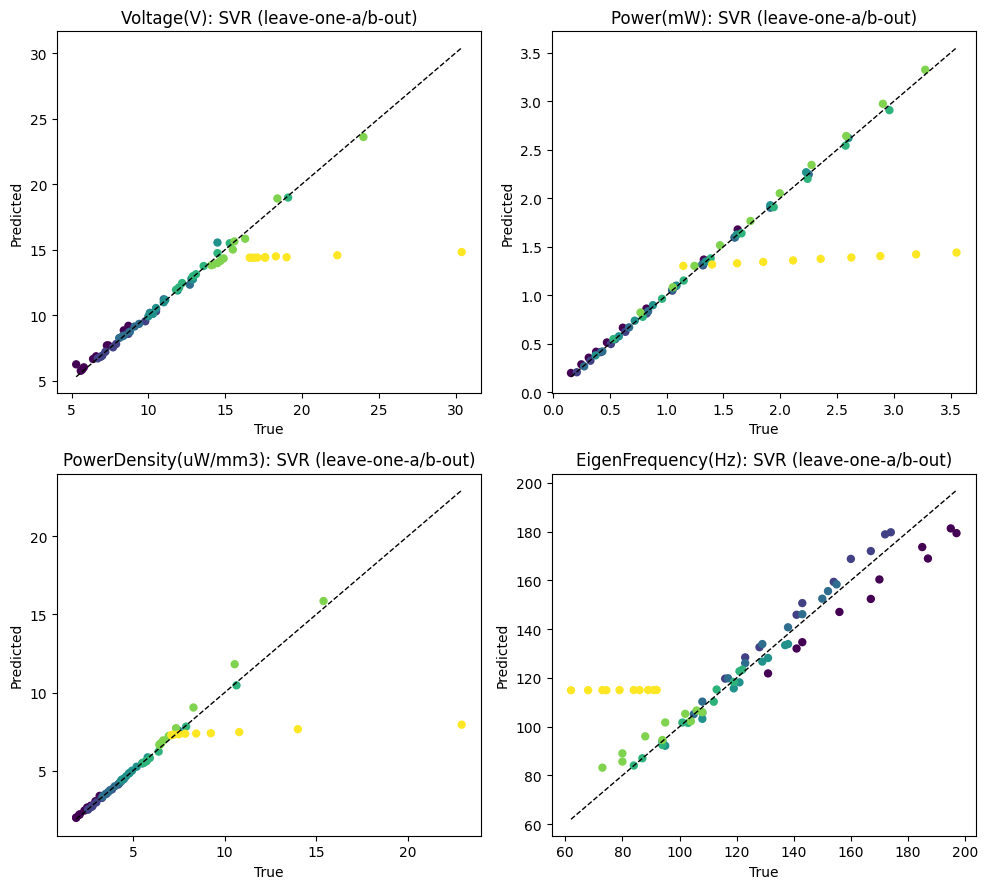

C. Mean absolute % error by held-out a/b (edge ratios must extrapolate, so they are usually worst)


,Voltage(V),Power(mW),PowerDensity(uW/mm3),EigenFrequency(Hz)
a/b,,,,
0.25000,5.55,9.01,5.00,7.09
0.42857,1.22,1.41,1.09,3.95
0.66667,1.11,0.96,0.47,2.14
1.00000,1.31,1.12,0.86,2.42
1.50000,1.04,1.35,1.48,1.06
2.33300,2.64,3.05,5.14,5.65
4.00000,22.51,35.56,18.89,46.35


Prediction for a/b = 3.0, coverage = 15 %:
{'Voltage(V)': 24.974820701379045, 'Power(mW)': 1.0768007034239062, 'PowerDensity(uW/mm3)': 16.247969733817314, 'EigenFrequency(Hz)': 80.43329006634838}


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def score(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return dict(R2=r2_score(y, p),
                RMSE=float(np.sqrt(mean_squared_error(y, p))),
                MAE=mean_absolute_error(y, p),
                MAPE_pct=100 * np.mean(np.abs((y - p) / y)))

# ---- A. Held-out test set (the 14 rows the models never saw) ----
rows = []
for tgt in TARGETS:
    for name in GRIDS:
        model, _ = fitted[(tgt, name)]
        rows.append(dict(Target=tgt, Model=name, **score(Y_te[tgt], model.predict(X_te))))
test_tbl = pd.DataFrame(rows)
print("A. Held-out test set: R2")
display(test_tbl.pivot(index="Target", columns="Model", values="R2").round(4))
print("A. Held-out test set: MAPE (%)")
display(test_tbl.pivot(index="Target", columns="Model", values="MAPE_pct").round(2))

# ---- B. Leave-one-a/b-out validation (tougher, more honest) ----
# Neighbouring coverage rows at the same a/b are near-duplicates, so a random split is optimistic.
# Here every a/b ratio is held out in turn and predicted by a model trained on the other ratios.
X_all, Y_all, groups = df[FEATURES], df[TARGETS], df["a/b"].values
logo = LeaveOneGroupOut()
rows, oof = [], {}
for tgt in TARGETS:
    for name in GRIDS:
        model, _ = fitted[(tgt, name)]
        p = cross_val_predict(clone(model), X_all, Y_all[tgt], groups=groups, cv=logo, n_jobs=-1)
        oof[(tgt, name)] = p
        rows.append(dict(Target=tgt, Model=name, **score(Y_all[tgt], p)))
logo_tbl = pd.DataFrame(rows)
print("B. Leave-one-a/b-out: R2")
display(logo_tbl.pivot(index="Target", columns="Model", values="R2").round(4))
print("B. Leave-one-a/b-out: MAPE (%)")
display(logo_tbl.pivot(index="Target", columns="Model", values="MAPE_pct").round(2))

# ---- C. Best model per target (by leave-one-a/b-out R2) + where its errors are largest ----
# MAPE reflects typical-case error; R2 is dominated by the few extreme rows (e.g. a/b=4 at 10 % coverage).
# Tree models predict piecewise-constant steps, so they interpolate poorly between the few a/b values in this dataset.
best = logo_tbl.loc[logo_tbl.groupby("Target")["MAPE_pct"].idxmin()].set_index("Target")["Model"]
print("Best model per target (lowest leave-one-a/b-out MAPE):", best.to_dict())

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, tgt in zip(axes.ravel(), TARGETS):
    y, p = Y_all[tgt].values, oof[(tgt, best[tgt])]
    ax.scatter(y, p, c=np.log(groups), cmap="viridis", s=25)
    lo, hi = min(y.min(), p.min()), max(y.max(), p.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_title(f"{tgt}: {best[tgt]} (leave-one-a/b-out)")
    ax.set_xlabel("True"); ax.set_ylabel("Predicted")
plt.tight_layout(); plt.show()

err = pd.DataFrame({"a/b": groups})
for tgt in TARGETS:
    err[tgt] = np.abs(Y_all[tgt].values - oof[(tgt, best[tgt])]) / Y_all[tgt].values * 100
print("C. Mean absolute % error by held-out a/b (edge ratios must extrapolate, so they are usually worst)")
display(err.groupby("a/b").mean().round(2))

# ---- D. Predict a new design ----
def predict_design(a_b, coverage_pct):
    if not (df["a/b"].min() <= a_b <= df["a/b"].max() and 10 <= coverage_pct <= 100):
        print("WARNING: outside the training range, so this is extrapolation and unreliable.")
    x = pd.DataFrame([[a_b, coverage_pct]], columns=FEATURES)
    return {tgt: float(fitted[(tgt, best[tgt])][0].predict(x)[0]) for tgt in TARGETS}

print("Prediction for a/b = 3.0, coverage = 15 %:")
print(predict_design(3.0, 15))
